In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [ ]:
df = pd.read_csv('/content/train (2).csv')
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
df.shape

(1460, 81)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [ ]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [ ]:
df.isnull().sum()

,0
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,259
LotArea,0
...,...
MoSold,0
YrSold,0
SaleType,0
SaleCondition,0


In [ ]:
df.isnull().sum()[df.isnull().sum() > 0]

,0
LotFrontage,259
Alley,1369
MasVnrType,872
MasVnrArea,8
BsmtQual,37
BsmtCond,37
BsmtExposure,38
BsmtFinType1,37
BsmtFinType2,38
Electrical,1


In [ ]:
top_5_corr = df.corr(numeric_only=True)['SalePrice'].drop('SalePrice').sort_values(ascending=False).head(5)

print("SalePrice bilan eng yuqori korrelyatsiyadagi 5 ta belgi:")
print(top_5_corr)

SalePrice bilan eng yuqori korrelyatsiyadagi 5 ta belgi:
OverallQual    0.790982
GrLivArea      0.708624
GarageCars     0.640409
GarageArea     0.623431
TotalBsmtSF    0.613581
Name: SalePrice, dtype: float64


In [ ]:
display(df)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


In [ ]:
import pandas as pd
import numpy as np
print(df.columns)

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

SalePrice      1.000000
OverallQual    0.790982
GrLivArea      0.708624
GarageCars     0.640409
GarageArea     0.623431
TotalBsmtSF    0.613581
1stFlrSF       0.605852
FullBath       0.560664
Name: SalePrice, dtype: float64


<Axes: >

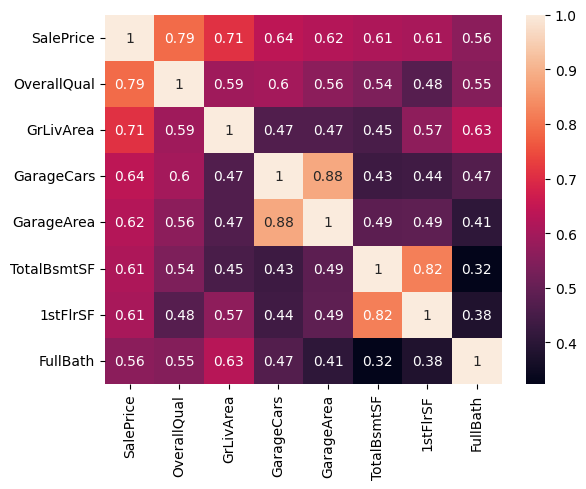

In [ ]:
num = df.select_dtypes(include=['number'])
c = num.corr()['SalePrice']
print(c.sort_values(ascending=False).head(8))

import seaborn as sns
cols = c.sort_values(ascending=False).head(8).index
sns.heatmap(df[cols].corr(), annot=True)

Text(0, 0.5, 'SalePrice')

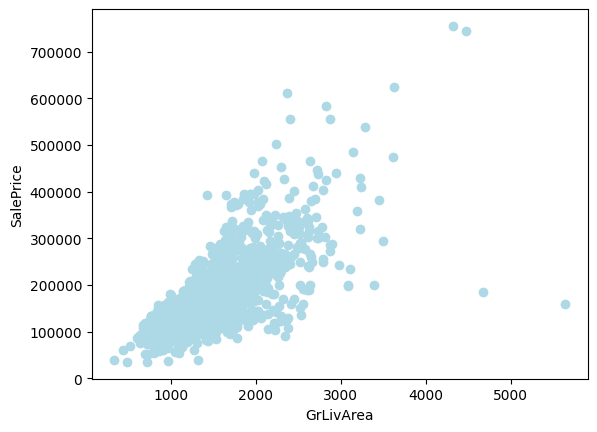

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(df['GrLivArea'], df['SalePrice'], color='lightblue')
plt.xlabel('GrLivArea')
plt.ylabel('SalePrice')

In [ ]:
# from google.colab import data_table
# data_table.DataTable(df)

In [ ]:
threshold = len(df) * 0.5
df = df.dropna(thresh=threshold, axis=1)
df = df.drop(columns=['Id'], errors='ignore')
df.shape

(1460, 75)

In [ ]:
from sklearn.linear_model import LinearRegression
X=df[['GrLivArea']]
y=df[['SalePrice']]

model=LinearRegression()
model.fit(X,y)

print("w=", model.coef_[0])
print("b=", model.intercept_)
print("R^2=", model.score(X,y))


w= [107.13035897]
b= [18569.02585649]
R^2= 0.5021486502718042


In [ ]:
yangi=pd.DataFrame({"GrLivArea":[1500, 2000]})
p=model.predict(yangi)
print(p.round(0))

[[179265.]
 [232830.]]


In [ ]:
from sklearn.linear_model import LinearRegression
X=df[['TotalBsmtSF']]
y=df[['SalePrice']]

model=LinearRegression()
model.fit(X,y)

print("w=", model.coef_[0])
print("b=", model.intercept_)
print("R^2=", model.score(X,y))


w= [111.10960369]
b= [63430.62854551]
R^2= 0.37648109325168655


In [ ]:
yangi=pd.DataFrame({"TotalBsmtSF":[2000, 1000]})
p=model.predict(yangi)
print(p.round(0))

[[285650.]
 [174540.]]


In [ ]:
from sklearn.linear_model import LinearRegression
X = df[['TotalBsmtSF', 'GrLivArea', 'OverallQual']]
y = df[['SalePrice']]

model = LinearRegression()
model.fit(X, y)

print("w=", model.coef_[0])
print("b=", model.intercept_)
print("R^2=", model.score(X, y))

w= [   36.61501735    49.45262987 28046.71532769]
b= [-103806.02063438]
R^2= 0.7420669639171528


In [ ]:
yangi=pd.DataFrame({"TotalBsmtSF":[2000, 1000], "GrLivArea":[1000,2000], "OverallQual":[4,8]})
p=model.predict(yangi)
print(p.round(0))

[[131064.]
 [256088.]]


In [ ]:
from sklearn.linear_model import LinearRegression
X=df[['OverallQual']]
y=df[['SalePrice']]

model=LinearRegression()
model.fit(X,y)

print("w=", model.coef_[0])
print("b=", model.intercept_)
print("R^2=", model.score(X,y))

w= [45435.8025931]
b= [-96206.07951476]
R^2= 0.625651892462118


In [ ]:
yangi=pd.DataFrame({"OverallQual":[1]})
p=model.predict(yangi)
print(p.round(0))

[[-50770.]]


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model.fit(X_train, y_train)
pred=model.predict(X_test)

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
mse = mean_squared_error(y_test, pred)
r2 = r2_score(y_test, pred)
mae=mean_absolute_error(y_test, pred)
rmse = np.sqrt(mse)  # RMSE hesaplama
print("MSE:", mse)
print("R^2:", r2)
print("MAE:", mae)
print("RMSE:", rmse)

MSE: 2681026163.5090904
R^2: 0.6504677778896863
MAE: 33343.24208697129
RMSE: 51778.62651238531


In [ ]:
from sklearn.dummy import DummyRegressor
dummy_regressor = DummyRegressor(strategy='mean')
dummy_regressor.fit(X_train, y_train)
y_pred = dummy_regressor.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
print("MSE:", mse)
print("R^2:", r2)
print("MAE:", mae)
print("RMSE:", rmse)


MSE: 7677095207.783831
R^2: -0.0008824918802490256
MAE: 62575.926451960964
RMSE: 87619.03450611533


In [ ]:
feats=[
    "GrLivArea", "TotalBsmtSF", "OverallQual", "YearBuilt", "GarageCars"
]
X=df[feats]
y=df["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
m=LinearRegression().fit(X_train, y_train)
print(dict(zip(feats, m.coef_.round(2))))
mse=mean_squared_error(y_test, m.predict(X_test))
print("MSE:", mse)
print("R^2:", r2_score(y_test, m.predict(X_test)))
print("MAE:", mean_absolute_error(y_test, m.predict(X_test)))
print("RMSE:", np.sqrt(mse))

{'GrLivArea': np.float64(48.81), 'TotalBsmtSF': np.float64(25.37), 'OverallQual': np.float64(20392.51), 'YearBuilt': np.float64(315.92), 'GarageCars': np.float64(15144.24)}
MSE: 1581119650.3936605
R^2: 0.7938653966356548
MAE: 25414.725402852193
RMSE: 39763.29526578073
